In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
from dotenv import load_dotenv
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
haley_df = pd.DataFrame(pd.read_csv('features_full.csv'))
haley_df

,date,y_pce_mom,y_pce_yoy,pce_L2,pce_L3,core_pce_L2,core_pce_L3,cpi_L2,cpi_L3,core_cpi_L2,...,ind_production_L3,retail_sales_L2,retail_sales_L3,sentiment_L1,sentiment_L2,sentiment_L3,m2_L2,m2_L3,month,covid_2020_2022
0,1999-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0
1,1999-02-01,-0.056040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,103.9,NaN,NaN,NaN,NaN,2,0
2,1999-03-01,0.075646,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,108.1,103.9,NaN,NaN,NaN,3,0
3,1999-04-01,0.481949,NaN,-0.056040,NaN,-0.034168,NaN,0.000000,NaN,0.000000,...,NaN,1.272517,NaN,105.7,108.1,103.9,0.498562,NaN,4,0
4,1999-05-01,0.065477,NaN,0.075646,-0.056040,0.030069,-0.034168,0.060698,0.000000,0.056931,...,0.606308,0.549554,1.272517,104.6,105.7,108.1,0.144571,0.498562,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,2026-07-01,0.050328,3.361543,0.434496,0.434855,0.309425,0.282481,0.471800,0.637998,0.207879,...,0.825415,1.029874,0.584781,49.5,44.8,49.8,1.123448,0.512371,7,0
331,2026-08-01,0.309799,3.419032,-0.102917,0.434496,0.133197,0.309425,-0.423377,0.471800,-0.016662,...,0.142621,0.202552,1.029874,55.2,49.5,44.8,0.438774,1.123448,8,0
332,2026-09-01,NaN,NaN,0.050328,-0.102917,0.126104,0.133197,0.073642,-0.423377,0.215203,...,0.231228,-0.407845,0.202552,51.7,55.2,49.5,0.444610,0.438774,9,0
333,2026-10-01,NaN,NaN,0.309799,0.050328,0.247134,0.126104,0.395236,0.073642,0.289377,...,0.232439,1.280546,-0.407845,48.1,51.7,55.2,0.536505,0.444610,10,0


## PCE - Components

Approximate shares of nominal PCE, 2024 (BEA NIPA Table 2.3.5).

| Component | Approx. Share of PCE |
|---|---|
| Durable Goods | ~10% |
| Nondurable Goods | ~21% |
| Housing & Utilities | ~17-18% |
| Healthcare | ~16-17% |
| Financial Services and Insurance | ~7-8% |
| Food Service and Accommodations | ~7% |
| Entertainment (Recreation Services) | ~4% |
| Transportation Services | ~3-4% |
| Other Services | ~8% |
| Nonprofits (NPISH) | ~3% |


## 1. Pull data from FRED

Everything comes from the FRED REST API (`fred/series/observations`) with plain `requests`, so no `fredapi` dependency. Each series is cached to `data/fred_raw/<ID>.csv` after its first download. **To refresh to the latest vintage, delete that folder and re-run.**

Notes on what FRED does and doesn't have (checked against the API on 2026-10-28):
- **Group targets.** FRED carries headline, core, energy, food (off-premises), *PCE ex food, energy & housing* (`IA001176M`) and *services ex energy & housing* (`IA001260M`), plus nominal spending for each. It does **not** carry monthly PCE price indexes for housing or core goods, so section 2 backs them out from those aggregates.
- **Units and precision traps.** `PCE`, `DNRGRC1M027SBEA` and `DFXARC1M027SBEA` are in **billions**, but `LA001176M` and `LA001260M` are in **millions**. `IA001176M` and `IA001260M` are rounded to **one decimal** (~±0.04 pp of rounding noise per monthly change, which the housing derivation amplifies about 5x). So those two price aggregates are rebuilt as implicit deflators, nominal (`LA…`) / real (`LB…`). Those exist from **2007** on, so housing and core goods start in 2007.
- **Missing on FRED:** CPI Rx drugs, CPI motor vehicle insurance, CPI recreation services (these need the BLS API). CPI Recreation (`CPIRECSL`) stands in for recreation services. The PPI for portfolio management (`PCU523920523920`) stops in 2022, so it's left out.
- **Short history:** FRED's `SP500` only starts in 2016 (licensing), so `NASDAQCOM` is pulled as a longer-history equity proxy.
- **Not seasonally adjusted:** the PPI hospital/physician/airline indexes, import prices, and all daily/weekly market series. Watch for seasonality in those.

In [3]:
PROJECT_DIR = Path.cwd()
FRED_CACHE_DIR = PROJECT_DIR / "data" / "fred_raw"
FRED_CACHE_DIR.mkdir(parents=True, exist_ok=True)
FRED_OBSERVATIONS_URL = "https://api.stlouisfed.org/fred/series/observations"
PULL_START = "1990-01-01"

load_dotenv(PROJECT_DIR / ".env")
FRED_API_KEY = os.environ["FRED_API_KEY"]

# Fixed group order and colors (validated default categorical palette, slots 1-5).
GROUPS = ["energy", "food", "core_goods", "housing", "services_ex"]
GROUP_COLORS = dict(zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
GROUP_LABELS = {"energy": "Energy", "food": "Food at home", "core_goods": "Core goods", "housing": "Housing", "services_ex": "Services ex-housing & energy"}
COVID_START, COVID_END = pd.Timestamp("2020-03-01"), pd.Timestamp("2022-12-01")

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.5, "legend.frameon": False,
})

### Series catalog
`role` is one of `price_target` (PCE price index for a group), `nominal_weight` (nominal spending, SAAR, used for shares), `real_quantity` (real spending, used only to build precise deflators) or `proxy` (candidate predictor). `group` ties each proxy to the driver group it should explain (`headline` = for Option B / benchmarks).

In [4]:
SERIES_CATALOG = pd.DataFrame(
    [
        # PCE price indexes (targets) -- BEA via FRED
        ("PCEPI", "pce_headline", "headline", "price_target"),
        ("PCEPILFE", "pce_core", "headline", "price_target"),
        ("DNRGRG3M086SBEA", "pce_energy", "energy", "price_target"),
        ("DFXARG3M086SBEA", "pce_food", "food", "price_target"),
        ("IA001176M", "pce_ex_food_energy_housing", "headline", "price_target"),
        ("IA001260M", "pce_services_ex", "services_ex", "price_target"),
        # Nominal PCE spending (weights), $bn SAAR
        ("PCE", "nominal_headline", "headline", "nominal_weight"),
        ("DNRGRC1M027SBEA", "nominal_energy", "energy", "nominal_weight"),
        ("DFXARC1M027SBEA", "nominal_food", "food", "nominal_weight"),
        ("LA001176M", "nominal_ex_food_energy_housing", "headline", "nominal_weight"),
        ("LA001260M", "nominal_services_ex", "services_ex", "nominal_weight"),
        # Real spending (chained 2017 $mn) -> implicit deflators with full precision (2007+)
        ("LB001176M", "real_ex_food_energy_housing", "headline", "real_quantity"),
        ("LB001260M", "real_services_ex", "services_ex", "real_quantity"),
        # Energy proxies
        ("CUSR0000SETB01", "cpi_gasoline", "energy", "proxy"),
        ("CUSR0000SEHF01", "cpi_electricity", "energy", "proxy"),
        ("CUSR0000SEHF02", "cpi_utility_gas", "energy", "proxy"),
        ("GASREGW", "retail_gasoline_weekly", "energy", "proxy"),
        ("DCOILWTICO", "wti_oil", "energy", "proxy"),
        ("DHHNGSP", "henry_hub_gas", "energy", "proxy"),
        # Food proxies
        ("CUSR0000SAF11", "cpi_food_at_home", "food", "proxy"),
        ("WPSFD4111", "ppi_consumer_foods", "food", "proxy"),
        # Core goods proxies
        ("CUSR0000SACL1E", "cpi_core_goods", "core_goods", "proxy"),
        ("CUSR0000SETA01", "cpi_new_vehicles", "core_goods", "proxy"),
        ("CUSR0000SETA02", "cpi_used_cars", "core_goods", "proxy"),
        ("CUSR0000SAH3", "cpi_household_furnishings", "core_goods", "proxy"),
        ("CPIAPPSL", "cpi_apparel", "core_goods", "proxy"),
        ("IR4", "import_px_consumer_goods", "core_goods", "proxy"),
        ("DTWEXBGS", "usd_broad_index", "core_goods", "proxy"),
        # Housing proxies
        ("CUSR0000SEHA", "cpi_rent", "housing", "proxy"),
        ("CUSR0000SEHC", "cpi_oer", "housing", "proxy"),
        # Services ex-housing & energy proxies
        ("CUSR0000SASLE", "cpi_services_less_energy", "services_ex", "proxy"),
        ("CUSR0000SAM2", "cpi_medical_services", "services_ex", "proxy"),
        ("PCU622622", "ppi_hospitals", "services_ex", "proxy"),
        ("PCU621111621111", "ppi_physicians", "services_ex", "proxy"),
        ("CUSR0000SEFV", "cpi_food_away", "services_ex", "proxy"),
        ("CUSR0000SEHB", "cpi_lodging", "services_ex", "proxy"),
        ("CPIRECSL", "cpi_recreation", "services_ex", "proxy"),
        ("CUSR0000SETG01", "cpi_airline_fares", "services_ex", "proxy"),
        ("PCU481111481111", "ppi_airline_passenger", "services_ex", "proxy"),
        ("CUSR0000SETD", "cpi_vehicle_repair", "services_ex", "proxy"),
        ("CUSR0000SEEB", "cpi_tuition_childcare", "services_ex", "proxy"),
        ("CUSR0000SAG1", "cpi_personal_care", "services_ex", "proxy"),
        ("CES0500000003", "ahe_private", "services_ex", "proxy"),
        ("CES7000000003", "ahe_leisure_hospitality", "services_ex", "proxy"),
        ("SP500", "sp500", "services_ex", "proxy"),
        ("NASDAQCOM", "nasdaq_composite", "services_ex", "proxy"),
        # Headline-level proxies (Option B / benchmarks)
        ("CPIAUCSL", "cpi_headline", "headline", "proxy"),
        ("CPILFESL", "cpi_core", "headline", "proxy"),
    ],
    columns=["series_id", "name", "group", "role"],
)
print(SERIES_CATALOG.groupby(["role", "group"]).size().to_string())

role            group      
nominal_weight  energy          1
                food            1
                headline        2
                services_ex     1
price_target    energy          1
                food            1
                headline        3
                services_ex     1
proxy           core_goods      7
                energy          6
                food            2
                headline        2
                housing         2
                services_ex    16
real_quantity   headline        1
                services_ex     1


In [5]:
def fetch_fred_series(series_id: str) -> pd.Series:
    """Download every observation of one FRED series (latest vintage) from PULL_START onward."""
    response = requests.get(
        FRED_OBSERVATIONS_URL,
        params={"series_id": series_id, "api_key": FRED_API_KEY, "file_type": "json", "observation_start": PULL_START},
        timeout=30,
    )
    response.raise_for_status()
    observations = pd.DataFrame(response.json()["observations"])
    # FRED marks missing values (e.g. market holidays) with "."; to_numeric turns them into NaN.
    values = pd.to_numeric(observations["value"], errors="coerce")
    return pd.Series(values.to_numpy(), index=pd.to_datetime(observations["date"]).rename("date"), name=series_id)


def load_fred_series(series_id: str) -> pd.Series:
    """Return a FRED series from the local cache, downloading and caching it on first use."""
    cache_path = FRED_CACHE_DIR / f"{series_id}.csv"
    if cache_path.exists():
        return pd.read_csv(cache_path, index_col="date", parse_dates=True)[series_id]
    series = fetch_fred_series(series_id)
    series.to_csv(cache_path)
    return series


def to_monthly(series: pd.Series) -> pd.Series:
    """Average daily/weekly observations within each calendar month; monthly series pass through unchanged."""
    return series.dropna().resample("MS").mean()


raw_series = {series_id: load_fred_series(series_id) for series_id in SERIES_CATALOG["series_id"]}
print(f"Loaded {len(raw_series)} series into {FRED_CACHE_DIR}")

Loaded 48 series into C:\Users\aidan\OneDrive - The University of Chicago\MS APDS\Statistical Models for DS\Final Project\data\fred_raw


### Coverage check
Daily and weekly series are averaged to calendar months. Their missing values (market holidays) are dropped before averaging, and the table logs how many. **The latest month of a daily/weekly series is usually partial** (October 2026 runs only through the last trading day pulled), so don't treat it as a full-month average yet.

In [6]:
coverage_rows = []
for series_id, series in raw_series.items():
    native_frequency = pd.infer_freq(series.index[-60:]) or "irregular"
    coverage_rows.append({
        "series_id": series_id,
        "native_freq": native_frequency,
        "first_obs": series.first_valid_index().date(),
        "last_obs": series.last_valid_index().date(),
        "n_obs": series.notna().sum(),
        "n_missing_dropped": series.isna().sum(),
    })
coverage = SERIES_CATALOG.merge(pd.DataFrame(coverage_rows), on="series_id")
coverage

,series_id,name,group,role,native_freq,first_obs,last_obs,n_obs,n_missing_dropped
0,PCEPI,pce_headline,headline,price_target,MS,1990-01-01,2026-08-01,440,0
1,PCEPILFE,pce_core,headline,price_target,MS,1990-01-01,2026-08-01,440,0
2,DNRGRG3M086SBEA,pce_energy,energy,price_target,MS,1990-01-01,2026-08-01,440,0
3,DFXARG3M086SBEA,pce_food,food,price_target,MS,1990-01-01,2026-08-01,440,0
4,IA001176M,pce_ex_food_energy_housing,headline,price_target,MS,1990-01-01,2026-08-01,440,0
5,IA001260M,pce_services_ex,services_ex,price_target,MS,1990-01-01,2026-08-01,440,0
6,PCE,nominal_headline,headline,nominal_weight,MS,1990-01-01,2026-08-01,440,0
7,DNRGRC1M027SBEA,nominal_energy,energy,nominal_weight,MS,1990-01-01,2026-08-01,440,0
8,DFXARC1M027SBEA,nominal_food,food,nominal_weight,MS,1990-01-01,2026-08-01,440,0
9,LA001176M,nominal_ex_food_energy_housing,headline,nominal_weight,MS,1990-01-01,2026-08-01,440,0


In [7]:
monthly_levels = pd.DataFrame({
    SERIES_CATALOG.set_index("series_id").loc[series_id, "name"]: to_monthly(series)
    for series_id, series in raw_series.items()
})
# Calendar-month labels (first day of the month). Monthly data has no time of day, so no timezone applies;
# daily market series are US Eastern close prices averaged within the month.
monthly_levels = monthly_levels.asfreq("MS")
monthly_levels.index.name = "month"
print(f"monthly_levels shape: {monthly_levels.shape}, {monthly_levels.index.min():%Y-%m} to {monthly_levels.index.max():%Y-%m}, freq={monthly_levels.index.freqstr}")

monthly_levels shape: (442, 48), 1990-01 to 2026-10, freq=MS


## 2. Build the five group targets and weights

**Monthly % change:** `m_t = 100 * (P_t / P_{t-1} - 1)`. **Weights:** previous month's nominal share of total PCE.

Housing and core goods are derived from aggregates FRED does carry:
- nominal core = headline − food − energy
- nominal housing = core − (PCE ex food, energy & housing)
- nominal core goods = (ex food, energy & housing) − (services ex energy & housing)

For prices, an aggregate's monthly change ≈ the share-weighted sum of its parts' changes, using last month's nominal weights. So, for example:

`m_housing ≈ (N_core,t-1 · m_core − N_exFEH,t-1 · m_exFEH) / N_housing,t-1`

This is a first-order approximation of BEA's Fisher chain index. We check its size below by rebuilding headline from food + energy + core, which uses the same approximation but no derived series.

The ex-FEH and services-ex price changes come from implicit deflators (`100 · nominal / real`), not the rounded published indexes. The next cell checks that the deflator rounds back to the published index.

In [8]:
MILLIONS_PER_BILLION = 1000
implicit_deflator = pd.DataFrame({
    "ex_feh": 100 * monthly_levels["nominal_ex_food_energy_housing"] / monthly_levels["real_ex_food_energy_housing"],
    "services_ex": 100 * monthly_levels["nominal_services_ex"] / monthly_levels["real_services_ex"],
})
for column, published in [("ex_feh", "pce_ex_food_energy_housing"), ("services_ex", "pce_services_ex")]:
    rounding_gap = (implicit_deflator[column].round(1) - monthly_levels[published]).dropna()
    print(f"{column}: deflator rounded to 1 dp matches {published} in {100 * (rounding_gap.abs() < 1e-9).mean():.0f}% of {len(rounding_gap)} months; max gap {rounding_gap.abs().max():.1f}")

ex_feh: deflator rounded to 1 dp matches pce_ex_food_energy_housing in 90% of 236 months; max gap 0.1
services_ex: deflator rounded to 1 dp matches pce_services_ex in 91% of 236 months; max gap 0.1


In [9]:
def pct_change_monthly(levels: pd.DataFrame) -> pd.DataFrame:
    """Month-over-month % change; the first row of each series is NaN by construction."""
    return 100 * (levels / levels.shift(1) - 1)


nominal = pd.DataFrame({
    "headline": monthly_levels["nominal_headline"],
    "energy": monthly_levels["nominal_energy"],
    "food": monthly_levels["nominal_food"],
    "ex_feh": monthly_levels["nominal_ex_food_energy_housing"] / MILLIONS_PER_BILLION,
    "services_ex": monthly_levels["nominal_services_ex"] / MILLIONS_PER_BILLION,
})
nominal["core"] = nominal["headline"] - nominal["food"] - nominal["energy"]
nominal["housing"] = nominal["core"] - nominal["ex_feh"]
nominal["core_goods"] = nominal["ex_feh"] - nominal["services_ex"]

price_mom = pct_change_monthly(monthly_levels[["pce_headline", "pce_core", "pce_energy", "pce_food"]])
price_mom.columns = ["headline", "core", "energy", "food"]
price_mom[["ex_feh", "services_ex"]] = pct_change_monthly(implicit_deflator)

nominal_lag = nominal.shift(1)
price_mom["housing"] = (nominal_lag["core"] * price_mom["core"] - nominal_lag["ex_feh"] * price_mom["ex_feh"]) / nominal_lag["housing"]
price_mom["core_goods"] = (nominal_lag["ex_feh"] * price_mom["ex_feh"] - nominal_lag["services_ex"] * price_mom["services_ex"]) / nominal_lag["core_goods"]

group_mom = price_mom[GROUPS].dropna()
group_share = nominal_lag[GROUPS].div(nominal_lag["headline"], axis=0).loc[group_mom.index]
group_contribution = group_share * group_mom  # percentage points of headline monthly change
headline_mom = price_mom["headline"].loc[group_mom.index]
print(f"group_mom shape: {group_mom.shape}, {group_mom.index.min():%Y-%m} to {group_mom.index.max():%Y-%m}")
print(f"Rows dropped: {len(price_mom) - len(group_mom)} of {len(price_mom)} (real-spending deflators start 2007-01, so changes start 2007-02; trailing months not yet released)")
print(f"Shares sum to 1: max |sum - 1| = {(group_share.sum(axis=1) - 1).abs().max():.2e}")

group_mom shape: (235, 5), 2007-02 to 2026-08
Rows dropped: 207 of 442 (real-spending deflators start 2007-01, so changes start 2007-02; trailing months not yet released)
Shares sum to 1: max |sum - 1| = 2.22e-16


In [10]:
approximation_error = (headline_mom - group_contribution.sum(axis=1))
print("Aggregation check: headline monthly change minus the sum of group contributions (pp)")
print(f"  mean abs error {approximation_error.abs().mean():.4f} pp, max abs error {approximation_error.abs().max():.4f} pp (in {approximation_error.abs().idxmax():%Y-%m})")
print(f"  for scale: mean |headline monthly change| = {headline_mom.abs().mean():.3f} pp")

pce_index = monthly_levels["pce_headline"]
pce_yoy = 100 * (pce_index / pce_index.shift(12) - 1)
latest_month = pce_index.last_valid_index()
print(f"\nLatest PCE release month: {latest_month:%Y-%m}; YoY = {pce_yoy[latest_month]:.2f}%, MoM = {headline_mom[latest_month]:.3f}%")

features_full = pd.read_csv("features_full.csv", parse_dates=["date"]).set_index("date")
target_check = pd.concat([headline_mom.rename("fred_mom"), features_full["y_pce_mom"]], axis=1, join="inner").dropna()
print(f"features_full.csv y_pce_mom vs fresh FRED pull: {len(target_check)} months, max abs diff = {(target_check['fred_mom'] - target_check['y_pce_mom']).abs().max():.4f} pp (non-zero = revisions since that file was built)")

Aggregation check: headline monthly change minus the sum of group contributions (pp)
  mean abs error 0.0016 pp, max abs error 0.0209 pp (in 2020-04)
  for scale: mean |headline monthly change| = 0.229 pp

Latest PCE release month: 2026-08; YoY = 3.42%, MoM = 0.310%
features_full.csv y_pce_mom vs fresh FRED pull: 235 months, max abs diff = 0.0070 pp (non-zero = revisions since that file was built)


## 3. Exploratory analysis
### 3.1 Headline PCE inflation
These are two separate panels, not a dual axis, because YoY and MoM are on different scales. Grey shading marks the COVID window used by `covid_2020_2022`.

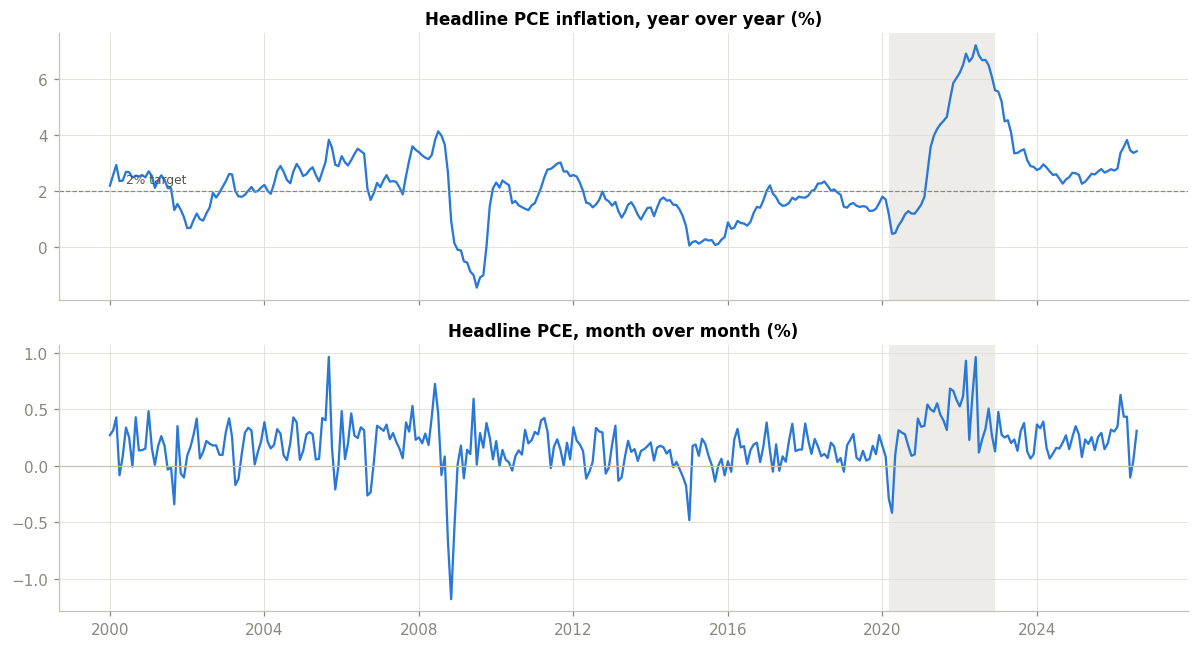

,pce_mom,pce_yoy
month,,
2025-06-01,0.255,2.612
2025-07-01,0.139,2.591
2025-08-01,0.255,2.694
2025-09-01,0.292,2.783
2025-10-01,0.148,2.657
2025-11-01,0.200,2.710
2025-12-01,0.320,2.777
2026-01-01,0.304,2.728
2026-02-01,0.348,2.801


In [11]:
fig, (ax_yoy, ax_mom) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
plot_window = slice("2000-01-01", None)
ax_yoy.plot(pce_yoy.loc[plot_window], color=GROUP_COLORS["energy"])
ax_yoy.axhline(2, color="#898781", linewidth=0.8, linestyle="--")
ax_yoy.text(pd.Timestamp("2000-06-01"), 2.3, "2% target", color="#52514e", fontsize=8)
ax_yoy.set_title("Headline PCE inflation, year over year (%)")
ax_mom.plot(price_mom["headline"].loc[plot_window], color=GROUP_COLORS["energy"])
ax_mom.axhline(0, color="#c3c2b7", linewidth=0.8)
ax_mom.set_title("Headline PCE, month over month (%)")
for ax in (ax_yoy, ax_mom):
    ax.axvspan(COVID_START, COVID_END, color="#e1e0d9", alpha=0.6, linewidth=0, zorder=0)
plt.tight_layout()
plt.show()

recent_months = pd.DataFrame({"pce_mom": headline_mom, "pce_yoy": pce_yoy}).loc["2025-06-01":].round(3)
recent_months

### 3.2 Group shares
These are nominal shares of total PCE. Compare them with the ~4 / 7.5 / 22 / 15 / 51% rule of thumb in CLAUDE.md.

Shares used for 2026-08 (previous month's nominal spending):
Energy                           3.8
Food at home                     7.1
Core goods                      21.7
Housing                         15.7
Services ex-housing & energy    51.7


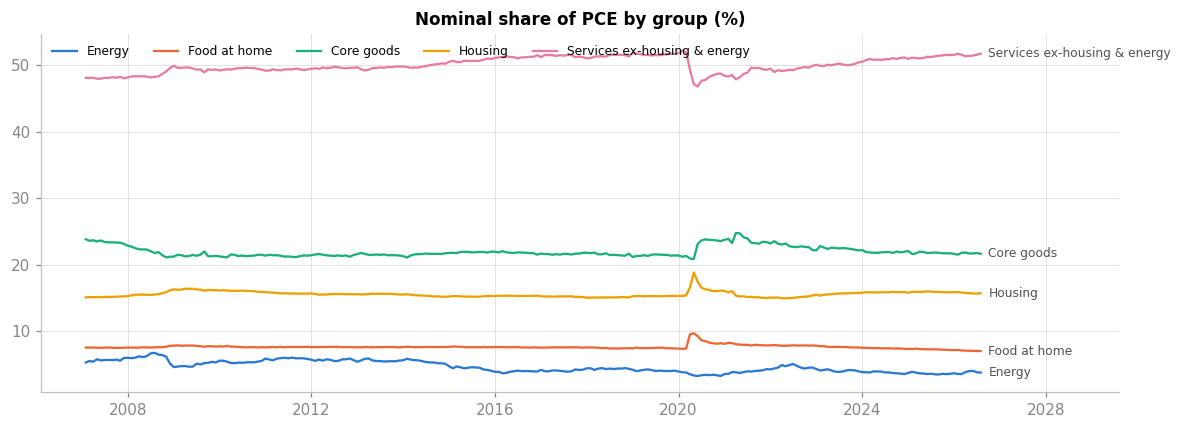

In [12]:
latest_shares = (100 * group_share.iloc[-1]).round(1).rename("latest_share_pct")
latest_shares.index = [GROUP_LABELS[group] for group in latest_shares.index]
print(f"Shares used for {group_share.index[-1]:%Y-%m} (previous month's nominal spending):")
print(latest_shares.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
for group in GROUPS:
    share_pct = 100 * group_share[group].loc[plot_window]
    ax.plot(share_pct, color=GROUP_COLORS[group], label=GROUP_LABELS[group])
    ax.text(share_pct.index[-1] + pd.Timedelta(days=60), share_pct.iloc[-1], GROUP_LABELS[group], color="#52514e", fontsize=8, va="center")
ax.set_title("Nominal share of PCE by group (%)")
ax.legend(loc="upper left", ncol=5, fontsize=8)
ax.set_xlim(right=share_pct.index[-1] + pd.Timedelta(days=1100))
plt.tight_layout()
plt.show()

### 3.3 Which groups drive headline volatility?
CLAUDE.md says effort should follow volatility, not share. Each group's contribution is `c_i,t = s_i,t-1 · m_i,t`, and headline ≈ Σ c_i. Two measures:
- **share² × variance**, i.e. `Var(c_i)`, is the group's own variance. It ignores covariances, so the column won't sum to the headline variance.
- **Covariance share**, `Cov(c_i, headline) / Var(headline)`, is an exact decomposition that sums to ~100%. It credits each group with its co-movement with headline, so a group that moves with energy picks up some of that credit.

We compute both over the full sample and over the 2015+ backtest window.

In [13]:
def volatility_decomposition(contribution: pd.DataFrame, group_changes: pd.DataFrame, shares: pd.DataFrame, headline: pd.Series) -> pd.DataFrame:
    """Per-group std of monthly change, Var(share*change), and covariance share of headline variance."""
    headline_variance = headline.var()
    table = pd.DataFrame({
        "std_mom_pp": group_changes.std(),
        "avg_share_pct": 100 * shares.mean(),
        "var_contribution": contribution.var(),
        "cov_share_of_headline_var_pct": 100 * contribution.apply(lambda column: column.cov(headline)) / headline_variance,
    })
    table["var_contribution_pct_of_sum"] = 100 * table["var_contribution"] / table["var_contribution"].sum()
    table.index = [GROUP_LABELS[group] for group in table.index]
    return table.round(3)


for label, window in [("Full sample 2007-2026", slice(None)), ("Backtest window 2015-2026", slice("2015-01-01", None))]:
    print(f"\n{label}: n = {len(headline_mom.loc[window])} months, std(headline MoM) = {headline_mom.loc[window].std():.3f} pp")
    display(volatility_decomposition(group_contribution.loc[window], group_mom.loc[window], group_share.loc[window], headline_mom.loc[window]))


Full sample 2007-2026: n = 235 months, std(headline MoM) = 0.224 pp


,std_mom_pp,avg_share_pct,var_contribution,cov_share_of_headline_var_pct,var_contribution_pct_of_sum
Energy,3.158,4.701,0.025,60.763,73.351
Food at home,0.350,7.669,0.001,2.953,2.371
Core goods,0.248,21.991,0.003,12.121,9.330
Housing,0.145,15.595,0.000,2.492,1.453
Services ex-housing & energy,0.137,50.044,0.005,21.630,13.495



Backtest window 2015-2026: n = 140 months, std(headline MoM) = 0.206 pp


,std_mom_pp,avg_share_pct,var_contribution,cov_share_of_headline_var_pct,var_contribution_pct_of_sum
Energy,2.998,4.070,0.016,47.575,59.086
Food at home,0.380,7.670,0.001,3.703,3.760
Core goods,0.293,22.146,0.005,19.481,16.936
Housing,0.137,15.527,0.000,3.111,1.632
Services ex-housing & energy,0.142,50.587,0.005,25.953,18.585


### 3.4 Contributions over time
Each panel shows one group's contribution to headline monthly change (share × change), in percentage points. **All panels share one y-axis**, so the heights compare directly. The view runs from 2015, the backtest window.

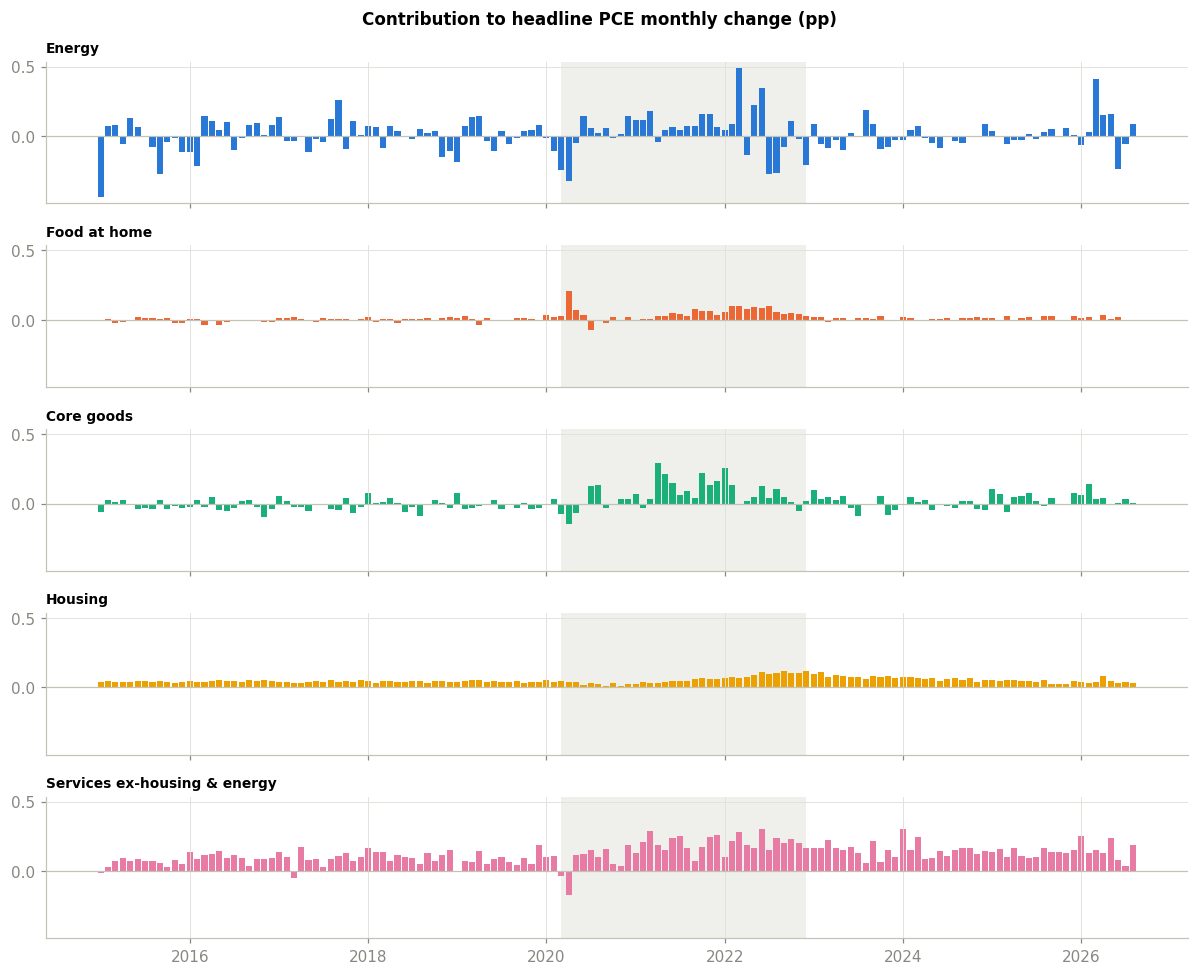

In [14]:
contribution_window = slice("2015-01-01", None)
fig, axes = plt.subplots(len(GROUPS), 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, group in zip(axes, GROUPS):
    series = group_contribution[group].loc[contribution_window]
    ax.bar(series.index, series.to_numpy(), width=25, color=GROUP_COLORS[group])
    ax.axhline(0, color="#c3c2b7", linewidth=0.8)
    ax.set_title(GROUP_LABELS[group], loc="left", fontsize=9)
    ax.axvspan(COVID_START, COVID_END, color="#e1e0d9", alpha=0.5, linewidth=0, zorder=0)
fig.suptitle("Contribution to headline PCE monthly change (pp)", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

### 3.5 Novembers and residual seasonality
These series are seasonally adjusted, so on average no calendar month should stand out. Residual seasonality would show up as a month that sits consistently above or below the rest. The calendar-month means use 2000–2025 with the COVID window excluded. The ex-energy column starts in 2007 because it needs the group contributions. The November panel starts in 2007 for the same reason. **Look at the median as well as the mean**, because one month like Nov 2008 (the oil collapse) can drag a 20-observation mean around.

Seasonality sample: 278 months (34 COVID-window months excluded)
Ex-energy column: 193 months (85 pre-2007 months have no group contributions)


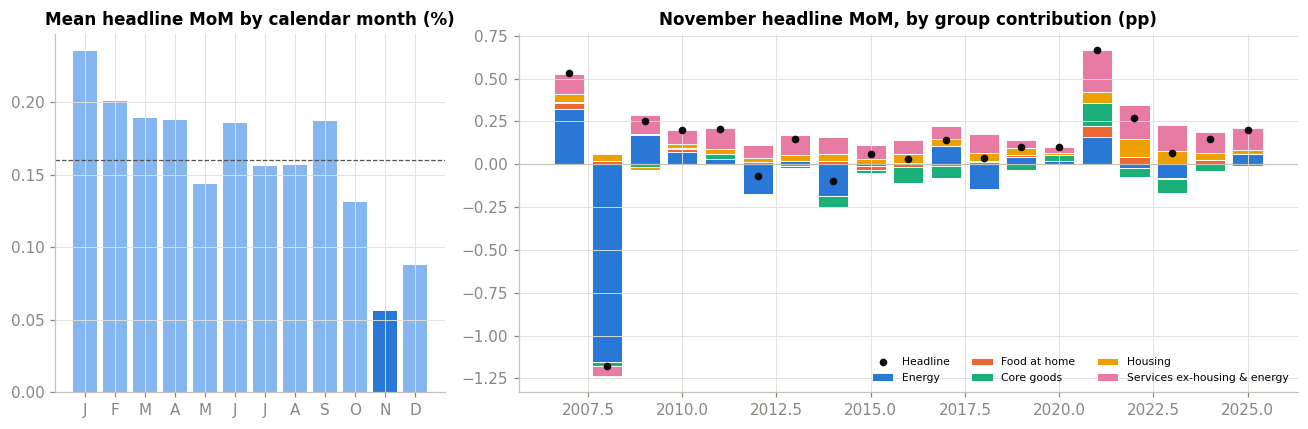

month,1,2,3,4,5,6,7,8,9,10,11,12
mean,0.235,0.201,0.189,0.187,0.143,0.186,0.156,0.157,0.187,0.131,0.056,0.088
median,0.285,0.206,0.194,0.186,0.163,0.175,0.134,0.148,0.190,0.160,0.103,0.102
std,0.212,0.116,0.154,0.159,0.139,0.182,0.127,0.138,0.260,0.230,0.311,0.196
count,24.000,24.000,23.000,23.000,23.000,23.000,23.000,23.000,23.000,23.000,23.000,23.000
mean_ex_energy_contrib,0.202,0.162,0.147,0.168,0.138,0.141,0.121,0.121,0.152,0.152,0.105,0.119
n_ex_energy,16.000,17.000,16.000,16.000,16.000,16.000,16.000,16.000,16.000,16.000,16.000,16.000


In [15]:
seasonal_sample = price_mom["headline"].loc["2000-01-01":"2025-12-01"]
seasonal_sample = seasonal_sample[(seasonal_sample.index < COVID_START) | (seasonal_sample.index > COVID_END)]
print(f"Seasonality sample: {len(seasonal_sample)} months ({len(price_mom['headline'].loc['2000-01-01':'2025-12-01']) - len(seasonal_sample)} COVID-window months excluded)")
mean_by_calendar_month = seasonal_sample.groupby(seasonal_sample.index.month).agg(["mean", "median", "std", "count"])
# Headline minus the energy contribution, to see whether a weak November is just oil-price timing.
headline_ex_energy = (headline_mom - group_contribution["energy"]).reindex(seasonal_sample.index).dropna()
print(f"Ex-energy column: {len(headline_ex_energy)} months ({len(seasonal_sample) - len(headline_ex_energy)} pre-2007 months have no group contributions)")
mean_by_calendar_month["mean_ex_energy_contrib"] = headline_ex_energy.groupby(headline_ex_energy.index.month).mean()
mean_by_calendar_month["n_ex_energy"] = headline_ex_energy.groupby(headline_ex_energy.index.month).size()

november_history = group_contribution[group_contribution.index.month == 11].loc["2000-01-01":]
november_headline = headline_mom[headline_mom.index.month == 11]

fig, (ax_season, ax_nov) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
bar_colors = ["#2a78d6" if month == 11 else "#86b6ef" for month in mean_by_calendar_month.index]
ax_season.bar(mean_by_calendar_month.index, mean_by_calendar_month["mean"], color=bar_colors)
ax_season.axhline(seasonal_sample.mean(), color="#52514e", linewidth=0.8, linestyle="--")
ax_season.set_xticks(range(1, 13), list("JFMAMJJASOND"))
ax_season.set_title("Mean headline MoM by calendar month (%)")

bottom_positive = np.zeros(len(november_history))
bottom_negative = np.zeros(len(november_history))
for group in GROUPS:
    values = november_history[group].to_numpy()
    bottoms = np.where(values >= 0, bottom_positive, bottom_negative)
    ax_nov.bar(november_history.index.year, values, bottom=bottoms, color=GROUP_COLORS[group], label=GROUP_LABELS[group], edgecolor="white", linewidth=0.6)
    bottom_positive += np.clip(values, 0, None)
    bottom_negative += np.clip(values, None, 0)
ax_nov.plot(november_headline.index.year, november_headline.to_numpy(), "o", color="#0b0b0b", markersize=4, label="Headline")
ax_nov.axhline(0, color="#c3c2b7", linewidth=0.8)
ax_nov.set_title("November headline MoM, by group contribution (pp)")
ax_nov.legend(fontsize=7, ncol=3, loc="lower right")
plt.tight_layout()
plt.show()
mean_by_calendar_month.round(3).T

### 3.6 Proxy vs target correlations
Each group's target is correlated with each of its proxies' monthly % change at **lag 0** and **lag 1**. With one month left to forecast, lag 0 is only legitimately available for the market series (gasoline, oil, natural gas, equities, dollar). For CPI and PPI, the lag-1 column is what we'll have in December. The sample is 2007+ (where every group target exists), `n` counts overlapping months, and pairs with missing data are dropped pairwise.

In [16]:
proxy_catalog = SERIES_CATALOG[SERIES_CATALOG["role"] == "proxy"]
proxy_mom = pct_change_monthly(monthly_levels[proxy_catalog["name"]])
target_frame = pd.concat([group_mom, headline_mom.rename("headline")], axis=1)
correlation_window = slice("2007-02-01", None)

correlation_rows = []
for _, proxy in proxy_catalog.iterrows():
    target = target_frame[proxy["group"]].loc[correlation_window]
    proxy_change = proxy_mom[proxy["name"]]
    correlation_rows.append({
        "group": proxy["group"],
        "proxy": proxy["name"],
        "corr_lag0": target.corr(proxy_change.loc[correlation_window]),
        "corr_lag1": target.corr(proxy_change.shift(1).loc[correlation_window]),
        "n": pd.concat([target, proxy_change], axis=1).dropna().shape[0],
    })
proxy_correlations = pd.DataFrame(correlation_rows).sort_values(["group", "corr_lag0"], ascending=[True, False]).round(3)
proxy_correlations

,group,proxy,corr_lag0,corr_lag1,n
8,core_goods,cpi_core_goods,0.814,0.478,233
12,core_goods,cpi_apparel,0.555,0.266,233
11,core_goods,cpi_household_furnishings,0.540,0.453,233
10,core_goods,cpi_used_cars,0.438,0.195,235
9,core_goods,cpi_new_vehicles,0.426,0.418,235
13,core_goods,import_px_consumer_goods,0.237,0.132,233
14,core_goods,usd_broad_index,-0.160,-0.120,235
0,energy,cpi_gasoline,0.986,0.330,235
3,energy,retail_gasoline_weekly,0.884,0.356,235
4,energy,wti_oil,0.611,0.499,235


### 3.7 Each group against its best contemporaneous proxy
These scatterplots preview the per-group OLS of Option A: fit, outliers, and whether a linear form looks reasonable.

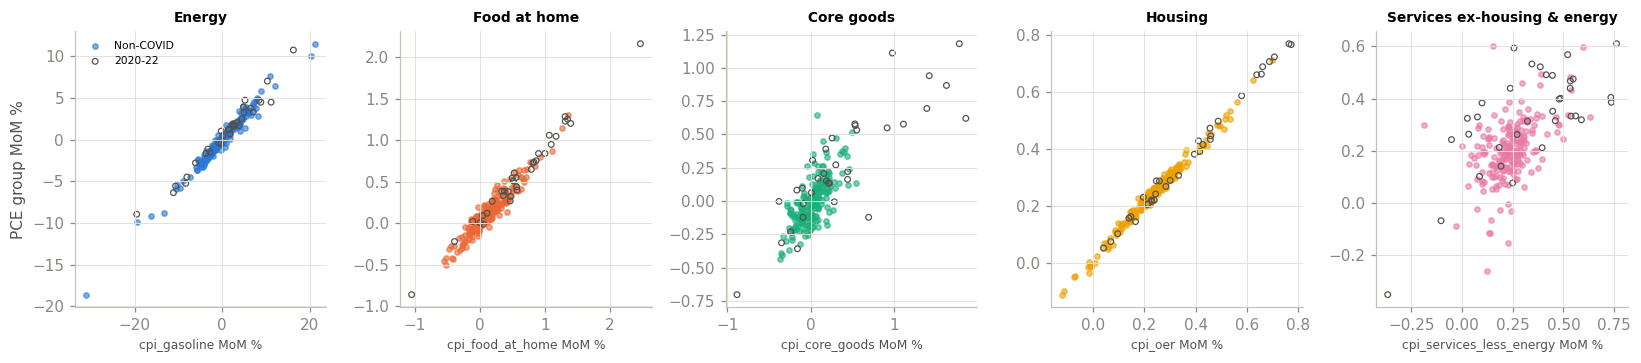

In [17]:
best_proxy = proxy_correlations[proxy_correlations["group"].isin(GROUPS)].sort_values("corr_lag0", ascending=False).groupby("group").head(1).set_index("group")["proxy"]
fig, axes = plt.subplots(1, len(GROUPS), figsize=(15, 3.4))
for ax, group in zip(axes, GROUPS):
    pair = pd.concat([proxy_mom[best_proxy[group]], group_mom[group]], axis=1).loc[correlation_window].dropna()
    in_covid = (pair.index >= COVID_START) & (pair.index <= COVID_END)
    ax.scatter(pair.iloc[~in_covid, 0], pair.iloc[~in_covid, 1], s=12, color=GROUP_COLORS[group], alpha=0.6, label="Non-COVID")
    ax.scatter(pair.iloc[in_covid, 0], pair.iloc[in_covid, 1], s=14, facecolors="none", edgecolors="#52514e", linewidth=0.8, label="2020-22")
    ax.set_title(GROUP_LABELS[group], fontsize=9)
    ax.set_xlabel(f"{best_proxy[group]} MoM %", fontsize=8)
axes[0].set_ylabel("PCE group MoM %")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

### 3.8 Collinearity preview among proxies
Highly correlated proxies within a group (for example CPI rent vs OER, or WTI vs retail gasoline) will inflate VIFs later. The colormap is diverging: orange for negative, neutral at 0, blue for positive.

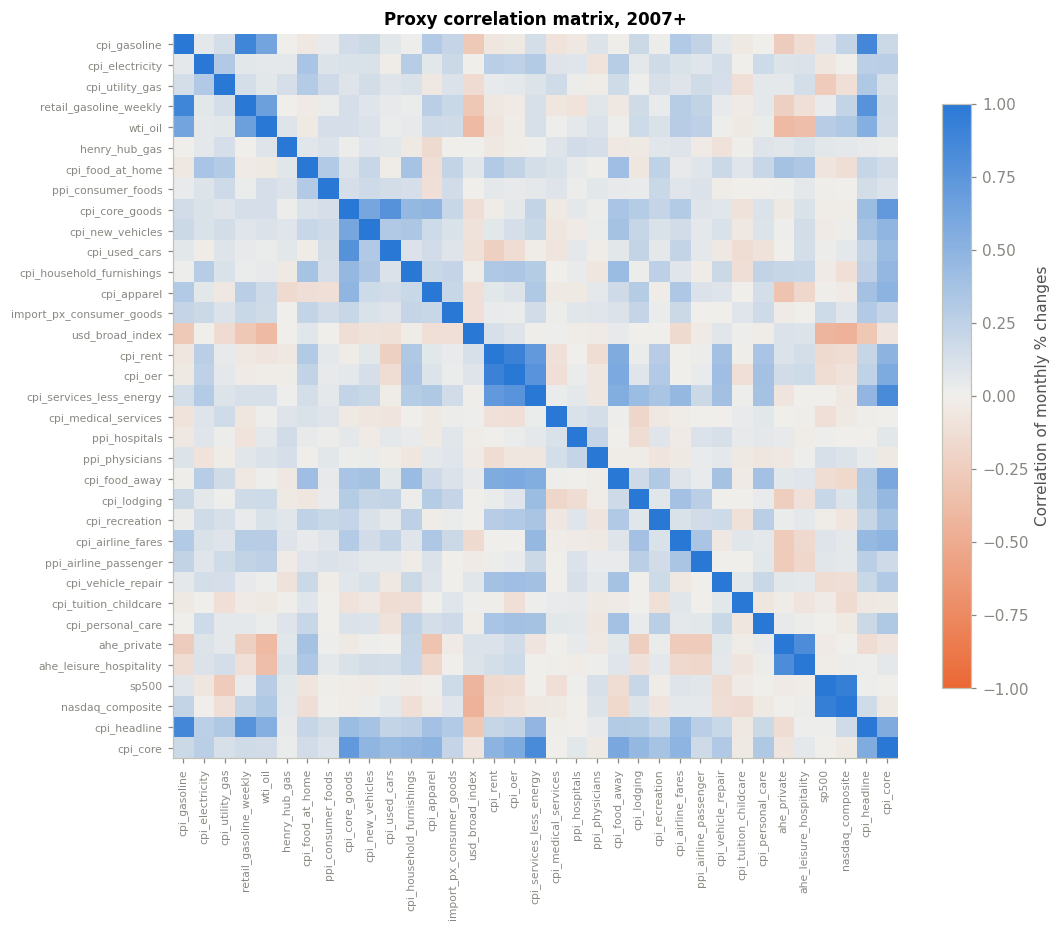

Proxy pairs with |corr| > 0.8:
sp500                     nasdaq_composite           0.936
cpi_rent                  cpi_oer                    0.911
cpi_gasoline              retail_gasoline_weekly     0.889
                          cpi_headline               0.860
cpi_services_less_energy  cpi_core                   0.836
ahe_private               ahe_leisure_hospitality    0.826


In [18]:
diverging_cmap = LinearSegmentedColormap.from_list("orange_gray_blue", ["#eb6834", "#f0efec", "#2a78d6"])
proxy_correlation_matrix = proxy_mom.loc[correlation_window].corr()
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(proxy_correlation_matrix, cmap=diverging_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(proxy_correlation_matrix)), proxy_correlation_matrix.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(proxy_correlation_matrix)), proxy_correlation_matrix.columns, fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.7, label="Correlation of monthly % changes")
ax.set_title("Proxy correlation matrix, 2007+")
plt.tight_layout()
plt.show()

upper_triangle = proxy_correlation_matrix.where(np.triu(np.ones(proxy_correlation_matrix.shape, dtype=bool), k=1))
high_pairs = upper_triangle.stack().loc[lambda pairs: pairs.abs() > 0.8].sort_values(ascending=False)
print("Proxy pairs with |corr| > 0.8:")
print(high_pairs.round(3).to_string())

## 4. Save the assembled monthly dataset
- `data/fred_monthly_levels.csv`: every series at monthly frequency, in levels.
- `data/pce_group_targets.csv`: group monthly changes, lagged shares, contributions, and headline MoM/YoY.

In [19]:
monthly_levels.to_csv(PROJECT_DIR / "data" / "fred_monthly_levels.csv")
group_targets = pd.concat(
    [group_mom.add_prefix("mom_"), group_share.add_prefix("share_"), group_contribution.add_prefix("contrib_"),
     headline_mom.rename("mom_headline"), pce_yoy.rename("yoy_headline")],
    axis=1,
).loc[group_mom.index]
group_targets.to_csv(PROJECT_DIR / "data" / "pce_group_targets.csv")
print(f"Saved fred_monthly_levels {monthly_levels.shape} and pce_group_targets {group_targets.shape}")

Saved fred_monthly_levels (442, 48) and pce_group_targets (235, 17)


## 5. Quick baseline model: one OLS regression for headline PCE (Option B)

A first, deliberately simple model to get a score on the board before the fuller predictor search in `PCE_analysis.ipynb`.

- **Target:** headline PCE monthly % change (`headline_mom`).
- **Predictors:** one proxy per driver group, plus the COVID dummy. Each one is lagged to match what we'll actually know in early December 2026:

| Predictor | Group | Lag | Why this lag |
|---|---|---|---|
| Retail gasoline price (EIA weekly, `GASREGW`) | Energy | 0 | Every November week is known by early December |
| CPI food at home | Food | 1 | October CPI is out mid-November; November CPI is not |
| CPI core goods | Core goods | 1 | Same |
| CPI owners' equivalent rent | Housing | 1 | Same |
| CPI services less energy | Services ex-housing & energy | 1 | Same |
| `covid_2020_2022` dummy | — | — | Absorbs the 2020–22 level shift |

All predictors are monthly % changes. PCE's own lags are **not** used (course gray area).

In [20]:
BASELINE_PREDICTORS = {
    # model column: (proxy series, lag in months, driver group)
    "gasoline_retail_L0": ("retail_gasoline_weekly", 0, "energy"),
    "cpi_food_at_home_L1": ("cpi_food_at_home", 1, "food"),
    "cpi_core_goods_L1": ("cpi_core_goods", 1, "core_goods"),
    "cpi_oer_L1": ("cpi_oer", 1, "housing"),
    "cpi_services_less_energy_L1": ("cpi_services_less_energy", 1, "services_ex"),
}
# Shift on the full monthly proxy index (freq=MS) so a lag of 1 is exactly one calendar month.
baseline_predictors = pd.DataFrame({column: proxy_mom[source].shift(lag) for column, (source, lag, _) in BASELINE_PREDICTORS.items()})
baseline_predictors["covid_2020_2022"] = ((baseline_predictors.index >= COVID_START) & (baseline_predictors.index <= COVID_END)).astype(float)
baseline_frame = pd.concat([headline_mom.rename("pce_mom"), baseline_predictors.reindex(headline_mom.index)], axis=1)

incomplete_rows = baseline_frame.isna().any(axis=1)
print(f"Dropped {incomplete_rows.sum()} of {len(baseline_frame)} months with a missing predictor: {[f'{month:%Y-%m}' for month in baseline_frame.index[incomplete_rows]]}")
print("  (BLS never published October 2025 CPI because of the federal shutdown, so lag-1 CPI changes are missing for Nov and Dec 2025.)")
baseline_frame = baseline_frame.loc[~incomplete_rows]
print(f"baseline_frame shape: {baseline_frame.shape}, {baseline_frame.index.min():%Y-%m} to {baseline_frame.index.max():%Y-%m}")

baseline_design = sm.add_constant(baseline_frame.drop(columns="pce_mom"))
baseline_fit = sm.OLS(baseline_frame["pce_mom"], baseline_design).fit()
predictor_groups = {column: group for column, (_, _, group) in BASELINE_PREDICTORS.items()} | {"const": "intercept", "covid_2020_2022": "dummy"}
coefficient_table = pd.DataFrame({
    "group": pd.Series(predictor_groups),
    "coef": baseline_fit.params,
    "std_err": baseline_fit.bse,
    "p_value": baseline_fit.pvalues,
    "vif": pd.Series([variance_inflation_factor(baseline_design.to_numpy(), i) for i in range(baseline_design.shape[1])], index=baseline_design.columns),
}).loc[baseline_design.columns]
coefficient_table.loc["const", "vif"] = np.nan  # VIF is not meaningful for the intercept
print(f"\nFull-sample fit: n = {int(baseline_fit.nobs)}, R² = {baseline_fit.rsquared:.3f}, adj. R² = {baseline_fit.rsquared_adj:.3f}, residual std = {np.sqrt(baseline_fit.scale):.3f} pp")
coefficient_table.round(4)

Dropped 2 of 235 months with a missing predictor: ['2025-11', '2025-12']
  (BLS never published October 2025 CPI because of the federal shutdown, so lag-1 CPI changes are missing for Nov and Dec 2025.)
baseline_frame shape: (233, 7), 2007-02 to 2026-08

Full-sample fit: n = 233, R² = 0.731, adj. R² = 0.724, residual std = 0.118 pp


,group,coef,std_err,p_value,vif
const,intercept,0.0397,0.0164,0.0160,NaN
gasoline_retail_L0,energy,0.0248,0.0012,0.0000,1.0265
cpi_food_at_home_L1,food,0.0745,0.0215,0.0006,1.2348
cpi_core_goods_L1,core_goods,0.0924,0.0282,0.0012,1.3862
cpi_oer_L1,housing,0.1011,0.0856,0.2388,2.6989
cpi_services_less_energy_L1,services_ex,0.2814,0.0869,0.0014,2.6257
covid_2020_2022,dummy,0.0864,0.0273,0.0018,1.5597


### 5.1 Score: expanding-window backtest
For every month from January 2015 on, fit the model on **all earlier months only**, predict that month, and record the error. This is the honest out-of-sample score. Random CV would leak future data into the fits.

Benchmarks: **last month's PCE change** and the **average of the last 3 months**. Both are naive and need no model. The score is MAE in percentage points (pp) of monthly change. With only November left to forecast, a monthly error of x pp moves the November YoY forecast by roughly x pp too.

Backtest: 138 months, 2015-01 to 2026-08 (34 in the COVID window)
Novembers in backtest: 10


,mae_pp,rmse_pp,mae_ex_covid_pp,mae_novembers_pp,mae_vs_last_month_pct
model,,,,,
ols_baseline,0.091,0.116,0.081,0.069,-34.852
last_month,0.140,0.195,0.124,0.091,0.000
avg_last_3_months,0.138,0.183,0.116,0.111,-1.637


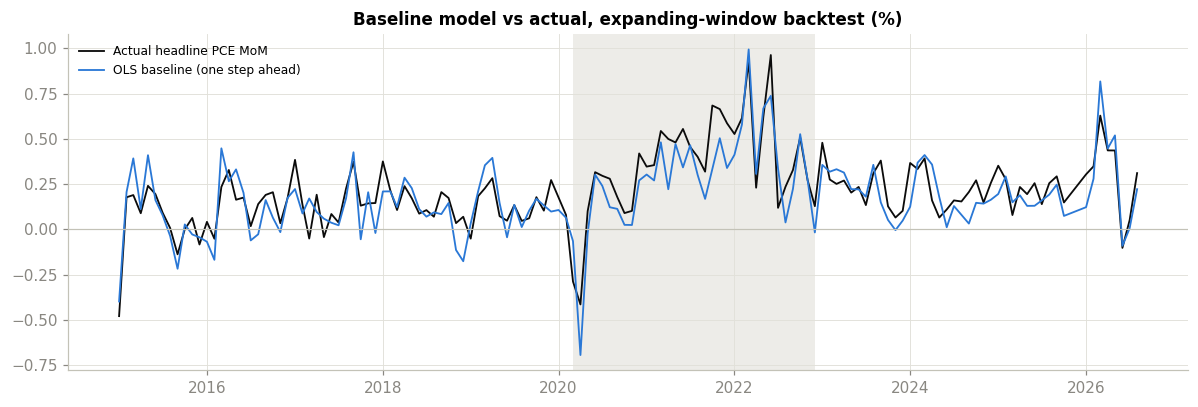

In [21]:
BACKTEST_START = pd.Timestamp("2015-01-01")


def expanding_window_predictions(frame: pd.DataFrame, target: str, start: pd.Timestamp) -> pd.Series:
    """For each month from `start` on, fit OLS on all earlier rows and predict that month."""
    predictions = {}
    for month in frame.loc[start:].index:
        train = frame.loc[frame.index < month]
        train_features = train.drop(columns=target)
        # A column that is constant in the training window (the COVID dummy before 2020-03) is aliased with the intercept.
        train_features = train_features.loc[:, train_features.nunique() > 1]
        fit = sm.OLS(train[target], sm.add_constant(train_features)).fit()
        test_row = sm.add_constant(frame.loc[[month], train_features.columns], has_constant="add")
        predictions[month] = float(fit.predict(test_row).iloc[0])
    return pd.Series(predictions, name="ols_baseline")


backtest_predictions = expanding_window_predictions(baseline_frame, "pce_mom", BACKTEST_START)
backtest = pd.DataFrame({
    "actual": baseline_frame["pce_mom"],
    "ols_baseline": backtest_predictions,
    "last_month": price_mom["headline"].shift(1),
    "avg_last_3_months": price_mom["headline"].shift(1).rolling(3).mean(),
}).loc[backtest_predictions.index]
in_covid_window = (backtest.index >= COVID_START) & (backtest.index <= COVID_END)
print(f"Backtest: {len(backtest)} months, {backtest.index.min():%Y-%m} to {backtest.index.max():%Y-%m} ({in_covid_window.sum()} in the COVID window)")

score_rows = []
for model in ["ols_baseline", "last_month", "avg_last_3_months"]:
    error = backtest["actual"] - backtest[model]
    score_rows.append({
        "model": model,
        "mae_pp": error.abs().mean(),
        "rmse_pp": np.sqrt((error ** 2).mean()),
        "mae_ex_covid_pp": error[~in_covid_window].abs().mean(),
        "mae_novembers_pp": error[backtest.index.month == 11].abs().mean(),
    })
backtest_scores = pd.DataFrame(score_rows).set_index("model")
backtest_scores["mae_vs_last_month_pct"] = 100 * (backtest_scores["mae_pp"] / backtest_scores.loc["last_month", "mae_pp"] - 1)
print(f"Novembers in backtest: {(backtest.index.month == 11).sum()}")
display(backtest_scores.round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(COVID_START, COVID_END, color="#e1e0d9", alpha=0.6, linewidth=0, zorder=0)
ax.plot(backtest.index, backtest["actual"], color="#0b0b0b", linewidth=1.2, label="Actual headline PCE MoM")
ax.plot(backtest.index, backtest["ols_baseline"], color=GROUP_COLORS["energy"], linewidth=1.2, label="OLS baseline (one step ahead)")
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_title("Baseline model vs actual, expanding-window backtest (%)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 6. Summary so far (plain English)

**The goal.** Forecast November 2026 headline PCE inflation (year over year). The monthly changes for Dec 2025 through Aug 2026 are already published. So the job is mostly to predict the last few monthly changes (Sep, Oct, Nov 2026) and chain them onto the known months.

**What we built**
1. **Data.** We pulled 48 series from FRED and saved them locally: PCE prices and spending, CPI and PPI pieces, gasoline, oil, natural gas, the dollar, stock indexes and wages. Everything is converted to monthly.
2. **Five driver groups.** We split headline PCE into energy, food at home, core goods, housing, and services ex-housing & energy. FRED doesn't publish monthly PCE prices for housing or core goods, so we backed them out from the aggregates it does publish.
   - **Sanity check:** weighting the five groups by their spending shares rebuilds headline almost exactly, with an average error of 0.002 pp against a typical monthly move of about 0.23 pp.
3. **Where inflation stands.** The latest release is August 2026: **3.42% year over year** and 0.31% month over month.
   - Inflation jumped in spring 2026 (March +0.63%, April and May about +0.44% each).
   - It then cooled in the summer (June −0.10%, July +0.05%).

**What the exploration showed**
- **Shares match the plan.** Services ex-housing & energy is 52% of spending, core goods 22%, housing 16%, food 7% and energy 4%.
- **Energy drives the month-to-month swings.** It is only about 4% of spending, but since 2015 it accounts for about half of the variation in headline monthly inflation. Housing is 16% of spending but only about 3% of the variation. So the energy forecast matters most.
- **November is usually a soft month.** Since 2000 it has had the lowest average monthly change (mean 0.06%, median 0.10%, against roughly 0.13–0.24% for other months).
  - Much of that is falling gas prices in some Novembers, with 2008 the extreme case.
  - With energy taken out, November is still on the low side but much closer to normal.
- **Same-month CPI would be an excellent predictor, but we won't have it.** CPI gasoline, CPI food at home and CPI OER each track their PCE group at a correlation of 0.97 or higher in the same month.
  - November CPI comes out after our presentation, so we can only use October CPI, a one-month lag. At that lag the correlations drop a lot (gasoline 0.33, food 0.57).
  - Housing is the exception (0.89), because rents move slowly.
  - Weekly retail gasoline prices are the key real-time signal: 0.88 correlation with PCE energy in the same month.
- **Some proxies are near-duplicates.** S&P 500 vs Nasdaq, rent vs OER, and CPI gasoline vs weekly gasoline each move together. A model should use one from each pair.

**Our first model (section 5)**
- **Setup:** one OLS regression of headline monthly PCE inflation on five predictors, one per group, plus a COVID dummy.
  - same-month retail gasoline prices
  - last month's CPI for food at home, core goods, owners' equivalent rent, and services less energy
- **In-sample fit:** R² = 0.73 (adjusted 0.72) on 233 months, 2007–2026. Gasoline is by far the strongest predictor.
- **Score:** in a fair backtest (2015–2026, predicting each month using only earlier data), the average miss is **0.09 pp**.
  - The naive "same as last month" rule misses by 0.14 pp, and the "3-month average" rule by 0.14 pp. The model cuts the typical error by about **35%**.
  - Leaving out the COVID years, the model's average miss is 0.08 pp.
  - On the 10 Novembers in the backtest, it misses by 0.07 pp on average ("same as last month" misses by 0.09 pp).
- **What that means for the forecast:** if only November is left to predict, the November YoY forecast would typically be off by roughly ±0.1 pp.

**Caveats**
- The backtest uses today's revised data, not what was known at the time, so the score is somewhat optimistic.
- Residuals are correlated month to month (Durbin–Watson 1.42) and fat-tailed, so the p-values are too optimistic.
- OER isn't significant once services CPI is in, because the two overlap.
- Two months (Nov–Dec 2025) were dropped because of the missing October 2025 CPI.

**Next steps**
- Run the fuller predictor search (forward/backward selection) in `PCE_analysis.ipynb`.
- Build the per-group models (Option A), the gamma GLM and the logistic model.
- Check influential periods with Cook's distance.
- Apply the models to Sep, Oct and Nov 2026 once October CPI (mid-November) and the November gasoline data are in.